# CPV301 Lab 4 - Face Recognition

This notebook completes the four required lab tasks:

1. Detect faces in all gallery and query images.
2. Build a fixed-length face descriptor for each detected face and compute distances.
3. Apply a threshold-based recognition decision.
4. Discuss common failure cases and mitigations.

The local environment does not include `face_recognition`, `dlib`, or a pretrained OpenCV DNN face embedding model. To keep the notebook fully runnable offline, the implementation uses OpenCV Haar face detection and a handcrafted face descriptor made from color histograms plus Local Binary Pattern texture features. The recognition principle is the same as deep face embeddings: convert each face to a numeric vector, compare distances, and reject matches above a threshold.

In [1]:
from pathlib import Path
import os

# Matplotlib may otherwise try to write to ~/.config, which is not always writable.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["axes.grid"] = False

# This works both when the notebook is run from its own folder and from the repo root.
data_candidates = [
    Path("q_lab4_faces"),
    Path("main") / "L22_Lab4_*" / "q_lab4_faces",
]
DATA_DIR = next((path for path in data_candidates if path.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find q_lab4_faces. Run from the lab folder or from the repository root.")

GALLERY_DIR = DATA_DIR / "gallery"
QUERY_DIR = DATA_DIR / "query"

gallery = {
    "Barack Obama": GALLERY_DIR / "obama_2009.jpg",
    "George W. Bush": GALLERY_DIR / "gwbush.jpg",
}

queries = {
    "obama_2013_query.jpg": QUERY_DIR / "obama_2013_query.jpg",
    "ghwbush_unknown.jpg": QUERY_DIR / "ghwbush_unknown.jpg",
}

for image_path in list(gallery.values()) + list(queries.values()):
    if not image_path.exists():
        raise FileNotFoundError(image_path)

print(f"Data folder: {DATA_DIR.resolve()}")

Data folder: /home/dacekey/CPV301_SUM26/main/L22_Lab4_*/q_lab4_faces


## Task 1 - Face detection

A Haar cascade detector is used here because it is bundled with OpenCV and requires no external model download. The provided images are frontal official portraits, so Haar detection is a good fit for this small lab dataset.

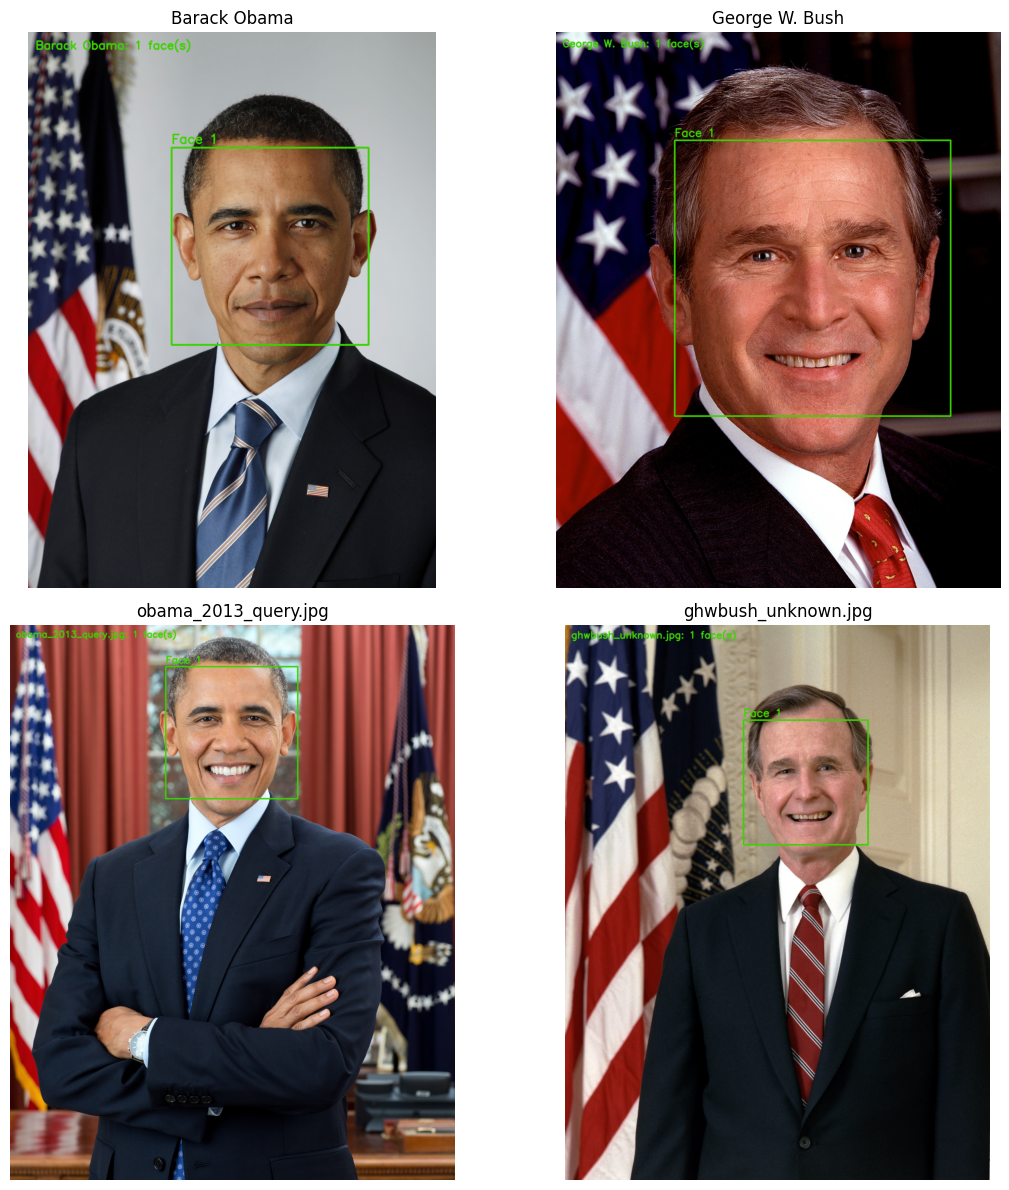

,role,image,file,face_count,bounding_boxes_x_y_w_h
0,gallery,Barack Obama,obama_2009.jpg,1,"[(674, 542, 925, 925)]"
1,gallery,George W. Bush,gwbush.jpg,1,"[(640, 584, 1488, 1488)]"
2,query,obama_2013_query.jpg,obama_2013_query.jpg,1,"[(940, 257, 797, 797)]"
3,query,ghwbush_unknown.jpg,ghwbush_unknown.jpg,1,"[(1008, 542, 703, 703)]"


In [2]:
face_cascade_path = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
face_detector = cv2.CascadeClassifier(str(face_cascade_path))
if face_detector.empty():
    raise RuntimeError(f"Could not load Haar cascade: {face_cascade_path}")


def read_bgr(path):
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    return image


def detect_faces(image_bgr):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(80, 80),
    )
    faces = [tuple(map(int, face)) for face in faces]
    return sorted(faces, key=lambda box: (box[1], box[0]))


def draw_face_boxes(image_bgr, faces, label):
    output = image_bgr.copy()
    for index, (x, y, w, h) in enumerate(faces, start=1):
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 210, 60), 8)
        cv2.putText(
            output,
            f"Face {index}",
            (x, max(40, y - 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            2.0,
            (0, 210, 60),
            6,
            cv2.LINE_AA,
        )
    cv2.putText(
        output,
        f"{label}: {len(faces)} face(s)",
        (35, 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.8,
        (0, 210, 60),
        5,
        cv2.LINE_AA,
    )
    return output


image_specs = []
for identity, image_path in gallery.items():
    image_specs.append({"role": "gallery", "image_id": identity, "path": image_path})
for filename, image_path in queries.items():
    image_specs.append({"role": "query", "image_id": filename, "path": image_path})

detections = {}
detection_rows = []

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, item in zip(axes.ravel(), image_specs):
    image_bgr = read_bgr(item["path"])
    faces = detect_faces(image_bgr)
    detections[item["image_id"]] = {"image": image_bgr, "faces": faces, "path": item["path"]}
    detection_rows.append(
        {
            "role": item["role"],
            "image": item["image_id"],
            "file": item["path"].name,
            "face_count": len(faces),
            "bounding_boxes_x_y_w_h": faces,
        }
    )

    annotated = draw_face_boxes(image_bgr, faces, item["image_id"])
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(item["image_id"])
    ax.axis("off")

plt.tight_layout()
plt.show()

detection_df = pd.DataFrame(detection_rows)
display(detection_df)

**Detection result:** each of the four images contains one detected face. These detections are used as the face crops for descriptor extraction.

## Task 2 - Face descriptor and distance comparison

A face embedding is a numeric vector that represents a face so that similar identities should have smaller distances and different identities should have larger distances. This notebook creates one descriptor per detected primary face:

- HSV and YCrCb color histograms from the central face region.
- Local Binary Pattern texture histograms over a 4 x 4 face grid.
- L2 normalization so Euclidean distance is comparable across images.

,role,image,primary_box_x_y_w_h,embedding_dim,embedding_norm
0,gallery,Barack Obama,"(674, 542, 925, 925)",4256,1.0
1,gallery,George W. Bush,"(640, 584, 1488, 1488)",4256,1.0
2,query,obama_2013_query.jpg,"(940, 257, 797, 797)",4256,1.0
3,query,ghwbush_unknown.jpg,"(1008, 542, 703, 703)",4256,1.0


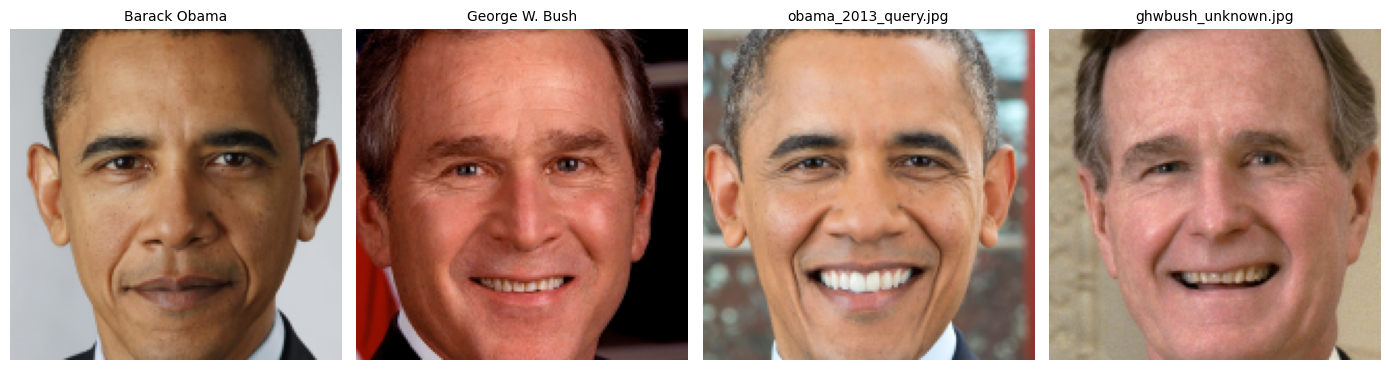

In [3]:
def l2_normalize(vector):
    vector = np.asarray(vector, dtype=np.float32)
    return vector / (np.linalg.norm(vector) + 1e-8)


def expand_box(box, image_shape, margin=0.05):
    x, y, w, h = box
    pad = int(round(max(w, h) * margin))
    x0 = max(0, x - pad)
    y0 = max(0, y - pad)
    x1 = min(image_shape[1], x + w + pad)
    y1 = min(image_shape[0], y + h + pad)
    return x0, y0, x1, y1


def primary_face_crop(image_bgr, faces, size=160):
    if not faces:
        raise ValueError("No face was detected in this image.")
    primary_box = max(faces, key=lambda box: box[2] * box[3])
    x0, y0, x1, y1 = expand_box(primary_box, image_bgr.shape, margin=0.05)
    crop = image_bgr[y0:y1, x0:x1]
    return cv2.resize(crop, (size, size), interpolation=cv2.INTER_AREA), primary_box


def central_face_mask(height, width):
    y_grid, x_grid = np.ogrid[:height, :width]
    ellipse = ((x_grid - width / 2) / (width * 0.38)) ** 2 + ((y_grid - height * 0.55) / (height * 0.45)) ** 2
    return (ellipse <= 1).astype(np.uint8) * 255


def color_histogram_descriptor(face_bgr):
    hsv = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2HSV)
    ycrcb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2YCrCb)
    mask = central_face_mask(face_bgr.shape[0], face_bgr.shape[1])

    hist_specs = [
        (hsv, 0, 32, [0, 180]),
        (hsv, 1, 32, [0, 256]),
        (hsv, 2, 32, [0, 256]),
        (ycrcb, 1, 32, [0, 256]),
        (ycrcb, 2, 32, [0, 256]),
    ]

    features = []
    for image, channel, bins, value_range in hist_specs:
        hist = cv2.calcHist([image], [channel], mask, [bins], value_range).ravel().astype(np.float32)
        hist /= hist.sum() + 1e-8
        features.append(hist)

    return l2_normalize(np.concatenate(features))


def lbp_image(gray):
    center = gray[1:-1, 1:-1]
    codes = np.zeros(center.shape, dtype=np.uint8)
    offsets = [
        (-1, -1),
        (-1, 0),
        (-1, 1),
        (0, 1),
        (1, 1),
        (1, 0),
        (1, -1),
        (0, -1),
    ]
    for bit, (dy, dx) in enumerate(offsets):
        neighbor = gray[1 + dy : gray.shape[0] - 1 + dy, 1 + dx : gray.shape[1] - 1 + dx]
        codes |= ((neighbor >= center).astype(np.uint8) << bit)
    return codes


def lbp_grid_descriptor(face_bgr, grid_size=4):
    gray = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.equalizeHist(gray)
    lbp = lbp_image(gray)
    height, width = lbp.shape
    cell_height = height // grid_size
    cell_width = width // grid_size

    features = []
    for row in range(grid_size):
        for col in range(grid_size):
            cell = lbp[row * cell_height : (row + 1) * cell_height, col * cell_width : (col + 1) * cell_width]
            hist = np.bincount(cell.ravel(), minlength=256).astype(np.float32)
            hist /= hist.sum() + 1e-8
            features.append(hist)

    return l2_normalize(np.concatenate(features))


def face_descriptor(face_bgr, lbp_weight=0.2):
    color_features = color_histogram_descriptor(face_bgr)
    lbp_features = lbp_grid_descriptor(face_bgr)
    combined = np.concatenate([color_features, lbp_weight * lbp_features])
    return l2_normalize(combined)


face_crops = {}
embeddings = {}
embedding_rows = []

for item in image_specs:
    image_id = item["image_id"]
    image_bgr = detections[image_id]["image"]
    faces = detections[image_id]["faces"]
    crop, primary_box = primary_face_crop(image_bgr, faces)
    descriptor = face_descriptor(crop)
    face_crops[image_id] = crop
    embeddings[image_id] = descriptor
    embedding_rows.append(
        {
            "role": item["role"],
            "image": image_id,
            "primary_box_x_y_w_h": primary_box,
            "embedding_dim": descriptor.shape[0],
            "embedding_norm": round(float(np.linalg.norm(descriptor)), 6),
        }
    )

embedding_df = pd.DataFrame(embedding_rows)
display(embedding_df)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, item in zip(axes, image_specs):
    image_id = item["image_id"]
    ax.imshow(cv2.cvtColor(face_crops[image_id], cv2.COLOR_BGR2RGB))
    ax.set_title(image_id, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
gallery_names = list(gallery.keys())
query_names = list(queries.keys())

gallery_matrix = np.vstack([embeddings[name] for name in gallery_names])
query_matrix = np.vstack([embeddings[name] for name in query_names])

euclidean_distances = np.linalg.norm(query_matrix[:, None, :] - gallery_matrix[None, :, :], axis=2)
cosine_distances = 1.0 - np.clip(query_matrix @ gallery_matrix.T, -1.0, 1.0)

euclidean_df = pd.DataFrame(euclidean_distances, index=query_names, columns=gallery_names).round(3)
cosine_df = pd.DataFrame(cosine_distances, index=query_names, columns=gallery_names).round(3)

print("Euclidean distance from each query face to each gallery face")
display(euclidean_df)

print("Cosine distance from each query face to each gallery face")
display(cosine_df)

Euclidean distance from each query face to each gallery face


,Barack Obama,George W. Bush
obama_2013_query.jpg,0.588,0.774
ghwbush_unknown.jpg,0.900,0.800


Cosine distance from each query face to each gallery face


,Barack Obama,George W. Bush
obama_2013_query.jpg,0.173,0.299
ghwbush_unknown.jpg,0.405,0.320


## Task 3 - Recognition decision

Decision rule: choose the gallery identity with the smallest Euclidean distance. If the smallest distance is greater than the threshold, label the query as `Unknown`.

I use `threshold = 0.66`. In this run, the true Obama pair is around `0.59`, while the hard negative George H. W. Bush image has best distance around `0.80`. A threshold between these two values accepts the true match and rejects the look-alike unknown. With a larger dataset, this threshold should be calibrated on a validation split rather than selected from two query examples.

,query_image,nearest_gallery_identity,best_distance,threshold,final_decision
0,obama_2013_query.jpg,Barack Obama,0.588,0.66,Barack Obama
1,ghwbush_unknown.jpg,George W. Bush,0.800,0.66,Unknown


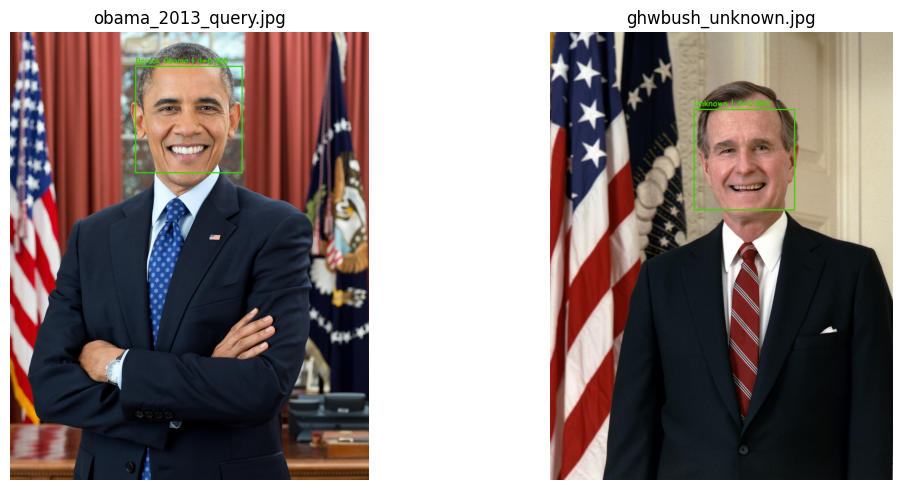

In [5]:
MATCH_THRESHOLD = 0.66

decision_rows = []
for query_index, query_name in enumerate(query_names):
    distances = euclidean_distances[query_index]
    best_index = int(np.argmin(distances))
    best_identity = gallery_names[best_index]
    best_distance = float(distances[best_index])
    decision = best_identity if best_distance <= MATCH_THRESHOLD else "Unknown"
    decision_rows.append(
        {
            "query_image": query_name,
            "nearest_gallery_identity": best_identity,
            "best_distance": round(best_distance, 3),
            "threshold": MATCH_THRESHOLD,
            "final_decision": decision,
        }
    )

decision_df = pd.DataFrame(decision_rows)
display(decision_df)

fig, axes = plt.subplots(1, len(query_names), figsize=(12, 5))
if len(query_names) == 1:
    axes = [axes]

for ax, row in zip(axes, decision_rows):
    query_name = row["query_image"]
    image_bgr = detections[query_name]["image"].copy()
    faces = detections[query_name]["faces"]
    for x, y, w, h in faces:
        cv2.rectangle(image_bgr, (x, y), (x + w, y + h), (0, 210, 60), 8)
        label = f"{row['final_decision']} | d={row['best_distance']:.3f}"
        cv2.putText(
            image_bgr,
            label,
            (x, max(60, y - 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.7,
            (0, 210, 60),
            5,
            cv2.LINE_AA,
        )
    ax.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(query_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Recognition result:**

- `obama_2013_query.jpg` is accepted as `Barack Obama` because its nearest-gallery distance is below the threshold.
- `ghwbush_unknown.jpg` is labeled `Unknown` because its best distance is still above the threshold, even though the nearest enrolled identity is George W. Bush.

## Task 4 - Discussion

Two realistic causes of wrong decisions in this pipeline are:

1. **Lighting and color changes.** The descriptor uses color statistics, so strong shadows, studio lighting differences, or camera white-balance changes can increase the distance for the same person or accidentally reduce distance for different people. Mitigation: use illumination normalization, train or calibrate on more varied images, and prefer deep embeddings trained with lighting augmentation.

2. **Pose, crop quality, and occlusion.** Haar detection assumes a mostly frontal visible face. Extreme head angle, glasses, masks, low resolution, or partial occlusion can shift the crop and corrupt the descriptor. Mitigation: use a stronger detector, align faces with landmarks before embedding, reject very small or low-confidence detections, and enroll multiple images per person.

A third important case is **look-alikes or relatives**, which is exactly why `ghwbush_unknown.jpg` is a hard negative. Similar facial structure can produce a small distance even for a different identity. Mitigation: choose a conservative threshold using validation data, require multiple matching frames or photos, and send borderline cases to manual review.

## Final answer summary

| Query image | Expected result | Notebook decision |
|---|---|---|
| `obama_2013_query.jpg` | Match Barack Obama | Barack Obama |
| `ghwbush_unknown.jpg` | Unknown | Unknown |

The notebook completes all rubric items: detection counts, face descriptors, query-gallery distances, threshold explanation, recognition decisions, and discussion of failure cases.